# Analýza a příprava dat – predikce pódia ve F1

Tento notebook pokrývá fáze **Data Understanding** a **Data Preparation** procesu CRISP-DM (přednáška 01).

**Rozhodovací problém:** Skončí jezdec v závodě na pódiu (1.–3. místo), když známe pouze informace dostupné **před startem**?

| | |
|---|---|
| instance | jeden jezdec v jednom závodě |
| cílová třída | `podium` (1 = ano, 0 = ne) |
| data | Jolpica F1 API, sezóny 2014–2026, stav k 17. 10. 2026 (`Stazeni_dat.ipynb`) |

**Postup podle přednášek a cvičení:**
1. Načtení a integrace zdrojů – přednáška 02, cvičení 2
2. Typy atributů, cílová třída – přednášky 03 a 04
3. Čištění nekonzistencí – přednáška 03
4. Statistiky a vizualizace – přednáška 03, cvičení 2
5. Chybějící a odlehlé hodnoty – přednáška 03, cvičení 1
6. Odvozené atributy (feature engineering) bez úniku dat – přednáška 03, cvičení 4
7. Korelace a multikolinearita – přednáška 03
8. Uložení tabulky pro modelování

> Imputace, kódování kategorií a škálování se záměrně **nedělají zde**, ale až v `Pipeline` po rozdělení dat na trénovací a testovací (přednáška 03, cvičení 4). Jinak by do trénování prosákly informace z testovacích dat.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

DATA = "../data"

## 1. Načtení a integrace dat
Tři CSV soubory spojíme do jedné tabulky (*data wrangling*, přednáška 03): k výsledkům závodu připojíme informace o závodě a kvalifikaci.

In [2]:
races = pd.read_csv(f"{DATA}/races.csv")
results = pd.read_csv(f"{DATA}/results.csv")
qualifying = pd.read_csv(f"{DATA}/qualifying.csv")

for name, d in [("races", races), ("results", results), ("qualifying", qualifying)]:
    print(f"{name:11s} {d.shape[0]:>5} řádků, {d.shape[1]:>2} sloupců")

races         275 řádků,  7 sloupců
results      5479 řádků, 14 sloupců
qualifying   5458 řádků,  7 sloupců


In [3]:
df = (results
      .merge(races, on=["season", "round"], how="left", validate="many_to_one")
      .merge(qualifying, on=["season", "round", "driver_id"], how="left", validate="one_to_one"))
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values(["date", "position"]).reset_index(drop=True)

print("tvar:", df.shape)
print("duplicitní instance (sezóna, kolo, jezdec):", df.duplicated(["season", "round", "driver_id"]).sum())
df.head()

tvar: (5479, 23)
duplicitní instance (sezóna, kolo, jezdec): 0


,season,round,driver_id,driver_code,driver_nationality,driver_dob,constructor_id,grid,position,position_text,points,laps,status,time_millis,race_name,date,circuit_id,circuit_name,country,quali_position,q1,q2,q3
0,2014,1,rosberg,ROS,German,1985-06-27,mercedes,3,1,1,25.0,57,Finished,5578710.0,Australian Grand Prix,2014-03-16,albert_park,Albert Park Grand Prix Circuit,Australia,3.0,1:32.564,1:42.264,1:44.595
1,2014,1,kevin_magnussen,MAG,Danish,1992-10-05,mclaren,4,2,2,18.0,57,Finished,5605487.0,Australian Grand Prix,2014-03-16,albert_park,Albert Park Grand Prix Circuit,Australia,4.0,1:30.949,1:43.247,1:45.745
2,2014,1,button,BUT,British,1980-01-19,mclaren,10,3,3,15.0,57,Finished,5608737.0,Australian Grand Prix,2014-03-16,albert_park,Albert Park Grand Prix Circuit,Australia,11.0,1:31.396,1:44.437,NaN
3,2014,1,alonso,ALO,Spanish,1981-07-29,ferrari,5,4,4,12.0,57,Finished,5613994.0,Australian Grand Prix,2014-03-16,albert_park,Albert Park Grand Prix Circuit,Australia,5.0,1:31.388,1:42.805,1:45.819
4,2014,1,bottas,BOT,Finnish,1989-08-28,williams,15,5,5,10.0,57,Finished,5626349.0,Australian Grand Prix,2014-03-16,albert_park,Albert Park Grand Prix Circuit,Australia,10.0,1:31.601,1:43.852,1:48.147


## 2. Typy atributů a cílová třída

| typ (přednáška 03) | atributy |
|---|---|
| nominální | `driver_id`, `constructor_id`, `circuit_id`, `country`, `status` |
| binární | `podium` (cíl) |
| ordinální | `grid`, `quali_position`, `position` |
| kvantitativní diskrétní | `points`, `laps`, `round` |
| kvantitativní spojité | časy Q1–Q3, `time_millis` |

**Pozor na únik dat:** `position`, `points`, `laps`, `status` a `time_millis` jsou známé **až po závodě**. Jako vstup modelu je použít nesmíme. Slouží jen k vytvoření cílové třídy a k výpočtu atributů z **předchozích** závodů.

Cílovou třídu vytvoříme **prahováním** cílové pozice (přednáška 03): `podium = position ≤ 3`.

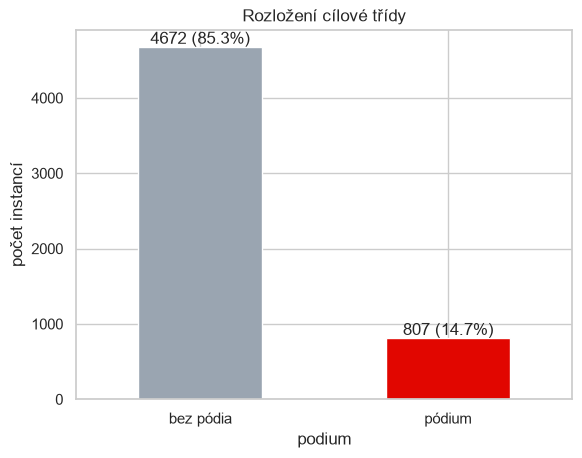

In [4]:
df["podium"] = (df["position"] <= 3).astype(int)

counts = df["podium"].value_counts().sort_index()
ax = counts.rename({0: "bez pódia", 1: "pódium"}).plot.bar(color=["#9aa5b1", "#e10600"], rot=0)
ax.set_title("Rozložení cílové třídy"); ax.set_ylabel("počet instancí")
for i, v in enumerate(counts): ax.text(i, v, f"{v} ({v / counts.sum():.1%})", ha="center", va="bottom")
plt.show()

Třídy jsou **nevyvážené**: na pódiu je jen ~15 % instancí. Podle přednášky 04 je proto samotná *accuracy* zavádějící. Model, který vždy tipne „bez pódia“, by měl accuracy ~85 % a přitom by nebyl k ničemu. Modely proto budeme hodnotit pomocí **precision, recall, F1 a ROC křivky**.

## 3. Čištění nekonzistencí
Přednáška 03 uvádí mezi typickými problémy dat **nekonzistenci** (různé zápisy téže věci). V našich datech jsou tři takové případy.

### 3.1 Status: 67 různých hodnot a změna formátu

In [5]:
print("počet různých statusů:", df["status"].nunique())
lapped = df[df["status"].str.contains("Lap")]
print(pd.crosstab(lapped["season"], lapped["status"].where(lapped["status"] == "Lapped", "+N Lap(s)")).T)

počet různých statusů: 67
season     2014  2015  2016  2017  2018  2019  2020  2021  2022  2023  2024  2025  2026
status                                                                                 
+N Lap(s)   121   126   176   140   144   164    92   164    87     0     0     0     0
Lapped        0     0     0     0     0     0     0     0     0    70   138    89   109


Do roku 2022 zdroj zapisuje dojetí o kolo jako `+1 Lap`, `+2 Laps`…, od roku 2023 jen jako `Lapped`. Statusy proto sloučíme do šesti skupin:

In [6]:
INCIDENT = {"Collision", "Accident", "Collision damage", "Spun off", "Damage", "Debris", "Puncture", "Front wing", "Rear wing"}
NOT_STARTED = {"Did not start", "Withdrew", "Illness"}
DSQ = {"Disqualified", "Excluded"}

def status_group(s):
    if s == "Finished":   return "dojel"
    if "Lap" in s:        return "dojel o kolo"
    if s in DSQ:          return "diskvalifikace"
    if s in NOT_STARTED:  return "neodstartoval"
    if s in INCIDENT:     return "nehoda"
    return "technická porucha"     # Engine, Gearbox, Brakes, Retired, Power Unit, ...

df["status_group"] = df["status"].map(status_group)
df["finished"] = df["status_group"].isin(["dojel", "dojel o kolo"]).astype(int)
df["tech_failure"] = (df["status_group"] == "technická porucha").astype(int)

df["status_group"].value_counts().to_frame("počet")

,počet
status_group,
dojel,2920
dojel o kolo,1620
technická porucha,623
nehoda,268
neodstartoval,30
diskvalifikace,18


### 3.2 Přejmenované týmy
Stejná stáj se v datech objevuje pod různými identifikátory. Bez sjednocení by se historie týmu (síla, spolehlivost) při každém přejmenování vynulovala. Zavedeme proto atribut `team`, který sleduje stáj, ne její název.

In [7]:
TEAM_LINEAGE = {
    "toro_rosso": "faenza", "alphatauri": "faenza", "rb": "faenza",
    "force_india": "silverstone", "racing_point": "silverstone", "aston_martin": "silverstone",
    "lotus_f1": "enstone", "renault": "enstone", "alpine": "enstone",
    "sauber": "hinwil", "alfa": "hinwil", "audi": "hinwil",
    "marussia": "banbury", "manor": "banbury",
}
df["team"] = df["constructor_id"].map(TEAM_LINEAGE).fillna(df["constructor_id"])

(df.groupby("team")["constructor_id"].unique()
   .map(lambda x: " → ".join(x)).to_frame("názvy v datech (chronologicky)")
   .query("`názvy v datech (chronologicky)`.str.contains('→')"))

,názvy v datech (chronologicky)
team,
banbury,marussia → manor
enstone,lotus_f1 → renault → alpine
faenza,toro_rosso → alphatauri → rb
hinwil,sauber → alfa → audi
silverstone,force_india → racing_point → aston_martin


### 3.3 Start z boxové uličky
`grid = 0` neznamená „lepší než 1. místo“, ale start z boxů, tedy úplně vzadu. V ordinální škále je to nesmyslná hodnota (přednáška 03: *inaccuracy*). Nahradíme ji posledním místem v daném závodě a informaci zachováme v binárním příznaku.

In [8]:
df["pit_lane_start"] = (df["grid"] == 0).astype(int)
field_size = df.groupby(["season", "round"])["driver_id"].transform("count")
df["grid_clean"] = df["grid"].where(df["grid"] > 0, field_size)
print("startů z boxů:", df["pit_lane_start"].sum())

startů z boxů: 54


## 4. Statistiky polohy, rozptylu a tvaru
Podle přednášky 03: průměr, medián, modus (poloha), směrodatná odchylka, IQR (rozptyl), šikmost a špičatost (tvar). Časy kvalifikace převedeme z textu `1:23.456` na sekundy.

In [9]:
def lap_to_sec(s):
    if pd.isna(s) or s == "":
        return np.nan
    m, sec = s.split(":") if ":" in s else ("0", s)
    return int(m) * 60 + float(sec)

for q in ["q1", "q2", "q3"]:
    df[f"{q}_sec"] = df[q].map(lap_to_sec)

num = ["grid_clean", "quali_position", "points", "laps", "q1_sec"]
summary = df[num].describe().T
summary["median"] = df[num].median()
summary["mode"] = df[num].mode().iloc[0]
summary["IQR"] = summary["75%"] - summary["25%"]
summary["skewness"] = df[num].skew()
summary["kurtosis"] = df[num].apply(lambda s: stats.kurtosis(s.dropna(), fisher=False))  # normální rozdělení = 3
summary.round(2)

,count,mean,std,min,25%,50%,75%,max,median,mode,IQR,skewness,kurtosis
grid_clean,5479.0,10.72,5.92,1.0,6.00,11.00,16.00,22.00,11.00,20.00,10.00,0.02,1.82
quali_position,5457.0,10.66,5.88,1.0,6.00,11.00,16.00,22.00,11.00,15.00,10.00,0.02,1.83
points,5479.0,4.99,7.21,0.0,0.00,0.00,8.00,50.00,0.00,0.00,8.00,1.45,4.25
laps,5479.0,53.68,17.91,0.0,51.00,56.00,66.00,87.00,56.00,70.00,15.00,-1.55,5.28
q1_sec,5377.0,87.26,13.03,53.9,77.12,87.45,95.22,141.61,87.45,75.99,18.11,0.48,3.17


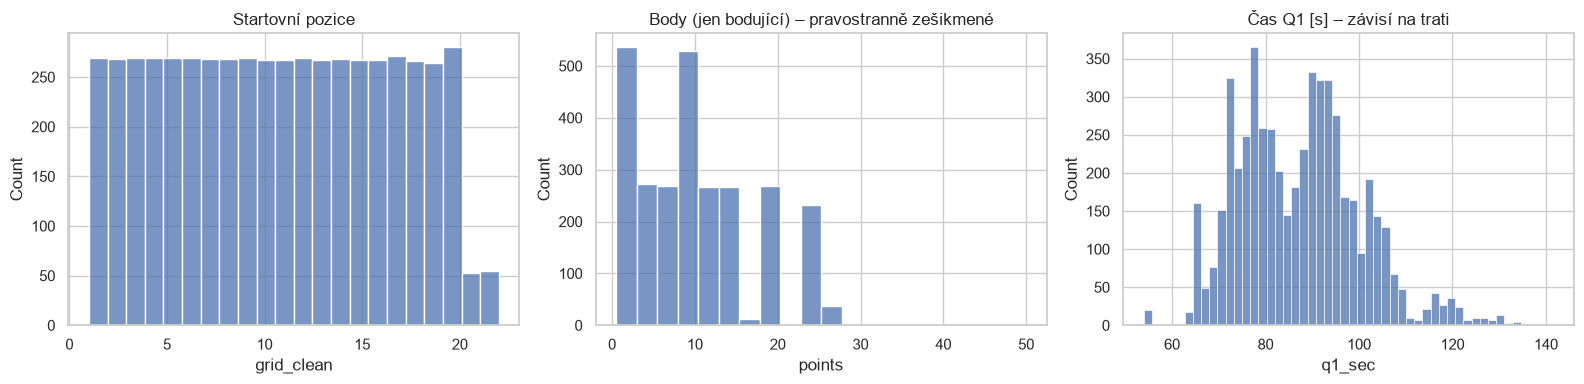

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df["grid_clean"], bins=22, ax=axes[0]).set_title("Startovní pozice")
sns.histplot(df.loc[df["points"] > 0, "points"], bins=20, ax=axes[1]).set_title("Body (jen bodující) – pravostranně zešikmené")
sns.histplot(df["q1_sec"].dropna(), bins=50, ax=axes[2]).set_title("Čas Q1 [s] – závisí na trati")
plt.tight_layout(); plt.show()

- **Startovní pozice** má zhruba rovnoměrné rozdělení, protože v každém závodě je každá pozice obsazena jednou.
- **Body** jsou silně pravostranně zešikmené (pár vysokých hodnot za vítězství). U odvozených atributů z bodů proto v pipeline zvážíme logaritmickou transformaci nebo robust scaling (přednáška 03).
- **Čas Q1** má několik vrcholů, protože každá trať je jinak dlouhá. Absolutní čas mezi tratěmi srovnávat nelze. Jde o **kontextové odlehlé hodnoty** (přednáška 03), a proto ho převedeme na relativní ztrátu v rámci závodu (kapitola 5).

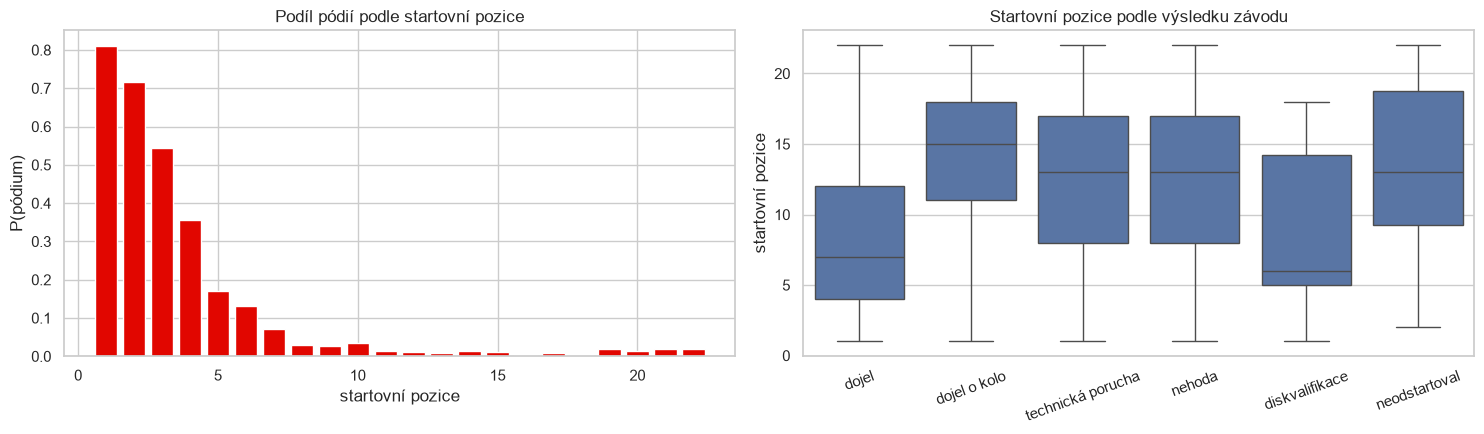

grid_clean
1    0.81
2    0.72
3    0.54
4    0.36
5    0.17
6    0.13


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
p_by_grid = df.groupby("grid_clean")["podium"].mean()
axes[0].bar(p_by_grid.index, p_by_grid.values, color="#e10600")
axes[0].set(title="Podíl pódií podle startovní pozice", xlabel="startovní pozice", ylabel="P(pódium)")

sns.boxplot(data=df, x="status_group", y="grid_clean", ax=axes[1],
            order=["dojel", "dojel o kolo", "technická porucha", "nehoda", "diskvalifikace", "neodstartoval"])
axes[1].set(title="Startovní pozice podle výsledku závodu", xlabel="", ylabel="startovní pozice")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

print(p_by_grid.head(6).round(2).to_string())

Startovní pozice je nejsilnější jednotlivý prediktor, ale výsledek **neurčuje**. Z pole position skončí na pódiu zhruba 4 z 5 jezdců, ze 3. místa jen asi polovina. Zbytek tvoří **šum**: porucha nebo nehoda, kterou z informací před startem předpovědět nejde.

In [12]:
dnf_pole = df[(df["grid_clean"] == 1) & (df["finished"] == 0)][["season", "race_name", "driver_id", "laps", "status"]]
print(f"Jezdci startující z pole position, kteří nedojeli: {len(dnf_pole)}")
dnf_pole.tail(8)

Jezdci startující z pole position, kteří nedojeli: 22


,season,race_name,driver_id,laps,status
3425,2022,Azerbaijan Grand Prix,leclerc,21,Power Unit
3505,2022,French Grand Prix,leclerc,17,Accident
3646,2022,United States Grand Prix,sainz,1,Collision damage
4066,2023,United States Grand Prix,leclerc,56,Disqualified
4205,2024,Australian Grand Prix,max_verstappen,3,Retired
4384,2024,British Grand Prix,russell,33,Retired
5063,2025,Las Vegas Grand Prix,norris,50,Disqualified
5211,2026,Canadian Grand Prix,russell,29,Retired


## 5. Chybějící a odlehlé hodnoty

### 5.1 Chybějící hodnoty

In [13]:
miss = (df[["grid", "quali_position", "q1", "q2", "q3", "time_millis"]]
        .isna().mean().mul(100).round(1).to_frame("% chybí"))
miss

,% chybí
grid,0.0
quali_position,0.4
q1,1.9
q2,27.1
q3,52.4
time_millis,38.7


Chybějící hodnoty tu **nejsou náhodné**. Podle přednášky 03 mohou nést informaci o cílové proměnné:

| atribut | proč chybí | řešení |
|---|---|---|
| `q2`, `q3` | jezdec vypadl v Q1/Q2 | **indikátor** `reached_q3` místo imputace |
| `quali_position`, `q1` | jezdec kvalifikaci nejel (penalizace, nehoda) | imputace v pipeline podle startovní pozice |
| `time_millis` | jezdec nedojel nebo byl dojet o kolo | do modelu **nepatří** (známé až po závodě) |

In [14]:
df["reached_q3"] = df["q3_sec"].notna().astype(int)
pd.crosstab(df["reached_q3"], df["podium"], normalize="index").round(3).rename(
    index={0: "nepostoupil do Q3", 1: "postoupil do Q3"}, columns={0: "bez pódia", 1: "pódium"})

podium,bez pódia,pódium
reached_q3,,
nepostoupil do Q3,0.987,0.013
postoupil do Q3,0.705,0.295


### 5.2 Ztráta na nejrychlejší čas a odlehlé hodnoty
Absolutní časy převedeme na **relativní ztrátu na nejrychlejšího v Q1 téhož závodu v %**. Q1 jezdí všichni, takže je to jediná část kvalifikace srovnatelná pro celé pole.

horní mez 1,5 × IQR: 3.46 %  → odlehlých: 262
99. percentil:       6.17 %


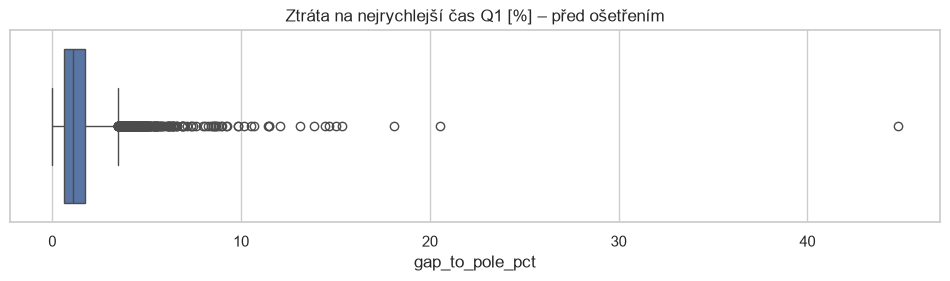

,season,race_name,driver_id,gap_to_pole_pct
3742,2023,Saudi Arabian Grand Prix,sargeant,44.782055
2765,2020,Turkish Grand Prix,latifi,20.535387
1025,2016,Hungarian Grand Prix,haryanto,18.099290
682,2015,Japanese Grand Prix,rossi,15.369868
1023,2016,Hungarian Grand Prix,wehrlein,15.048981
1024,2016,Hungarian Grand Prix,ericsson,14.664209
1716,2018,Azerbaijan Grand Prix,brendon_hartley,14.449277
3786,2023,Azerbaijan Grand Prix,de_vries,13.837403


In [15]:
best_q1 = df.groupby(["season", "round"])["q1_sec"].transform("min")
df["gap_to_pole_pct"] = (df["q1_sec"] / best_q1 - 1) * 100

q1_, q3_ = df["gap_to_pole_pct"].quantile([.25, .75])
upper_iqr = q3_ + 1.5 * (q3_ - q1_)
p99 = df["gap_to_pole_pct"].quantile(.99)
print(f"horní mez 1,5 × IQR: {upper_iqr:.2f} %  → odlehlých: {(df['gap_to_pole_pct'] > upper_iqr).sum()}")
print(f"99. percentil:       {p99:.2f} %")

plt.figure(figsize=(12, 2.5))
sns.boxplot(x=df["gap_to_pole_pct"]).set_title("Ztráta na nejrychlejší čas Q1 [%] – před ošetřením")
plt.show()
df[df["gap_to_pole_pct"] > upper_iqr].nlargest(8, "gap_to_pole_pct")[["season", "race_name", "driver_id", "gap_to_pole_pct"]]

Extrémní hodnoty (desítky procent) nejsou chyby měření. Jde o skutečné, ale výjimečné situace: déšť, poškozené auto, jezdec, který Q1 nedokončil. Podle přednášky 03 (*exceptional, but true values*) a cvičení 1 je **neodstraňujeme**. Ořízneme je na 99. percentil (*capping / winsorizace*) a jejich výskyt zachováme v příznaku `gap_outlier`.

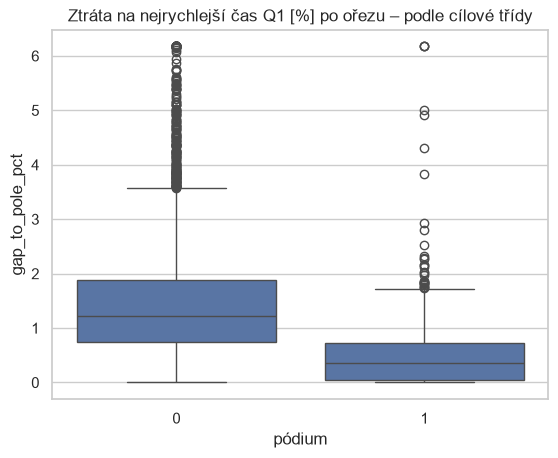

In [16]:
df["gap_outlier"] = (df["gap_to_pole_pct"] > p99).astype(int)
df["gap_to_pole_pct"] = df["gap_to_pole_pct"].clip(upper=p99)

sns.boxplot(data=df, x="podium", y="gap_to_pole_pct")
plt.title("Ztráta na nejrychlejší čas Q1 [%] po ořezu – podle cílové třídy"); plt.xlabel("pódium"); plt.show()

## 6. Odvozené atributy (feature engineering)

Model nesmí vidět jména jezdců. Učí se obecné vzorce, takže jezdce a tým popíšeme **čísly**. Všechny atributy počítáme **jen z předchozích závodů** (`shift(1)`), jinak by šlo o únik dat (cvičení 4).

| atribut | význam |
|---|---|
| `driver_form_pts` | průměr bodů jezdce za posledních 5 závodů |
| `driver_podium_rate` | podíl pódií jezdce za posledních 10 závodů |
| `champ_points_before` | body jezdce v šampionátu před závodem |
| `champ_rank_before` | pořadí jezdce v šampionátu před závodem |
| `team_form_pts` | průměr bodů týmu (obě auta) za posledních 5 závodů |
| `team_rank_before` | pořadí týmu v poháru konstruktérů před závodem |
| `team_tech_dnf_rate` | podíl technických poruch týmu za posledních 10 závodů (spolehlivost) |
| `driver_starts` | počet předchozích startů jezdce (zkušenost) |
| `is_rookie` | méně než 10 předchozích startů |
| `driver_age` | věk jezdce v den závodu |
| `track_top3_conversion` | jak často na této trati v minulých ročnících vyhrál pódium někdo z první trojice na startu |

*Omezení:* zdroj obsahuje jen body z hlavních závodů, body ze sprintů v nich nejsou. Pořadí v šampionátu proto může být mírně odlišné od oficiálního.

In [17]:
df = df.sort_values(["date", "position"]).reset_index(drop=True)

def past_rolling_mean(group_key, col, window):
    # průměr za posledních `window` závodů, BEZ aktuálního závodu
    return df.groupby(group_key)[col].transform(lambda s: s.shift(1).rolling(window, min_periods=1).mean())

# --- jezdec ---
df["driver_form_pts"] = past_rolling_mean("driver_id", "points", 5)
df["driver_podium_rate"] = past_rolling_mean("driver_id", "podium", 10)
df["driver_starts"] = df.groupby("driver_id").cumcount()
df["is_rookie"] = (df["driver_starts"] < 10).astype(int)
df["driver_age"] = (df["date"] - pd.to_datetime(df["driver_dob"])).dt.days / 365.25

# --- šampionát jezdců před závodem ---
df["champ_points_before"] = df.groupby(["season", "driver_id"])["points"].transform(lambda s: s.cumsum().shift(1)).fillna(0)
df["champ_rank_before"] = df.groupby(["season", "round"])["champ_points_before"].rank(ascending=False, method="min")

In [18]:
# --- tým: nejdřív souhrn za tým a závod, pak klouzavé hodnoty z předchozích závodů ---
team_race = (df.groupby(["team", "season", "round", "date"], as_index=False)
               .agg(team_points=("points", "sum"), team_tech=("tech_failure", "sum"), team_entries=("driver_id", "count"))
               .sort_values("date"))
g = team_race.groupby("team")
team_race["team_form_pts"] = g["team_points"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
team_race["team_tech_dnf_rate"] = (g["team_tech"].transform(lambda s: s.shift(1).rolling(10, min_periods=1).sum())
                                   / g["team_entries"].transform(lambda s: s.shift(1).rolling(10, min_periods=1).sum()))
team_race["team_champ_before"] = team_race.groupby(["team", "season"])["team_points"].transform(lambda s: s.cumsum().shift(1)).fillna(0)
team_race["team_rank_before"] = team_race.groupby(["season", "round"])["team_champ_before"].rank(ascending=False, method="min")

df = df.merge(team_race[["team", "season", "round", "team_form_pts", "team_tech_dnf_rate", "team_rank_before"]],
              on=["team", "season", "round"], how="left", validate="many_to_one")

In [19]:
# --- trať: jak často v minulých ročnících proměnil start z top 3 pódium ---
front = df[df["grid_clean"] <= 3]
track_race = (front.groupby(["circuit_id", "date"], as_index=False)["podium"].mean()
                   .rename(columns={"podium": "front_conv"}).sort_values("date"))
track_race["track_top3_conversion"] = (track_race.groupby("circuit_id")["front_conv"]
                                       .transform(lambda s: s.shift(1).expanding().mean()))
df = df.merge(track_race[["circuit_id", "date", "track_top3_conversion"]], on=["circuit_id", "date"], how="left")

print(df.groupby("circuit_id")["track_top3_conversion"].last().dropna().sort_values().round(2).to_string())

circuit_id
istanbul          0.33
losail            0.44
hungaroring       0.58
rodriguez         0.59
baku              0.59
interlagos        0.60
bahrain           0.64
red_bull_ring     0.64
hockenheimring    0.67
vegas             0.67
ricard            0.67
miami             0.67
silverstone       0.67
zandvoort         0.67
spa               0.69
monza             0.69
catalunya         0.69
americas          0.70
marina_bay        0.70
shanghai          0.71
albert_park       0.73
imola             0.75
suzuka            0.80
villeneuve        0.80
sochi             0.81
yas_marina        0.82
monaco            0.82
jeddah            0.83
sepang            0.92
portimao          1.00


### Kontrola úniku dat
Ukázka pro jednoho jezdce: atributy v řádku závodu *N* smí záviset jen na závodech *1 … N−1*. U prvního závodu sezóny jsou proto body v šampionátu 0 a u prvního startu v datech je forma prázdná.

In [20]:
cols = ["season", "round", "driver_id", "points", "driver_form_pts", "champ_points_before", "champ_rank_before", "team_form_pts"]
df[(df["driver_id"] == "max_verstappen") & (df["season"] == 2026)][cols].head(6)

,season,round,driver_id,points,driver_form_pts,champ_points_before,champ_rank_before,team_form_pts
5110,2026,1,max_verstappen,8.0,21.0,0.0,1.0,21.2
5142,2026,2,max_verstappen,0.0,19.6,8.0,6.0,19.8
5156,2026,3,max_verstappen,4.0,16.6,8.0,8.0,17.6
5175,2026,4,max_verstappen,10.0,12.4,12.0,9.0,13.4
5195,2026,5,max_verstappen,15.0,9.4,22.0,7.0,10.2
5236,2026,6,max_verstappen,0.0,7.4,37.0,6.0,10.2


### Chybějící hodnoty v odvozených atributech
Odvozené atributy chybí tam, kde chybí historie: první start jezdce, první závod týmu, první ročník trati. Jde o malou část dat. Doplní se v pipeline po rozdělení dat (medián nebo KNN imputace, přednáška 03).

In [21]:
FEATURES = ["grid_clean", "pit_lane_start", "quali_position", "gap_to_pole_pct", "gap_outlier", "reached_q3",
            "driver_form_pts", "driver_podium_rate", "champ_points_before", "champ_rank_before",
            "team_form_pts", "team_rank_before", "team_tech_dnf_rate",
            "driver_starts", "is_rookie", "driver_age", "track_top3_conversion"]
df[FEATURES].isna().mean().mul(100).round(1).to_frame("% chybí").query("`% chybí` > 0")

,% chybí
quali_position,0.4
gap_to_pole_pct,1.9
driver_form_pts,1.1
driver_podium_rate,1.1
team_form_pts,0.5
team_tech_dnf_rate,0.5
track_top3_conversion,12.6


## 7. Vztah atributů k cíli, korelace a multikolinearita

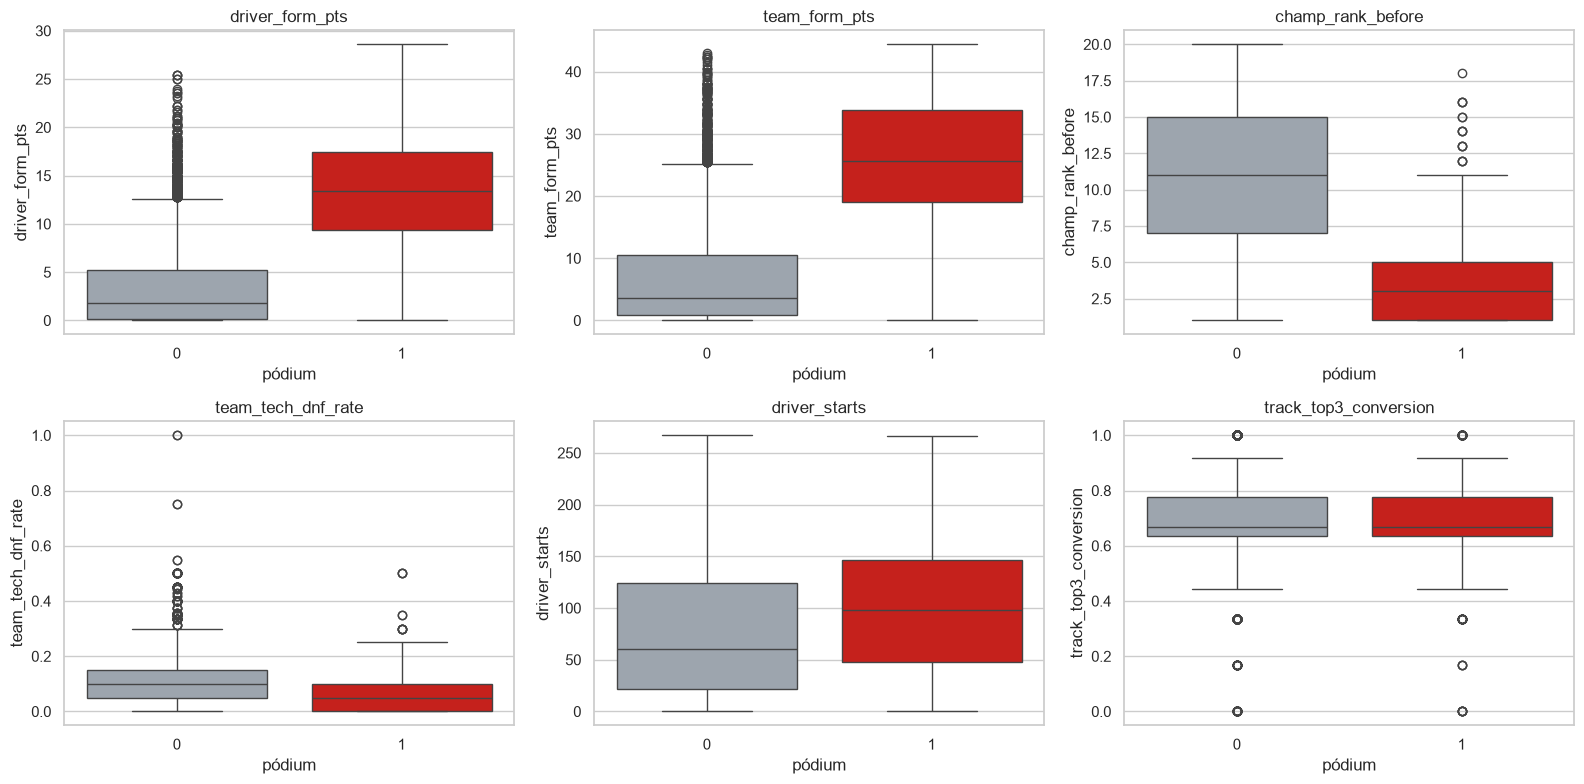

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, ["driver_form_pts", "team_form_pts", "champ_rank_before",
                               "team_tech_dnf_rate", "driver_starts", "track_top3_conversion"]):
    sns.boxplot(data=df, x="podium", y=col, ax=ax, hue="podium", palette={0: "#9aa5b1", 1: "#e10600"}, legend=False)
    ax.set_title(col); ax.set_xlabel("pódium")
plt.tight_layout(); plt.show()

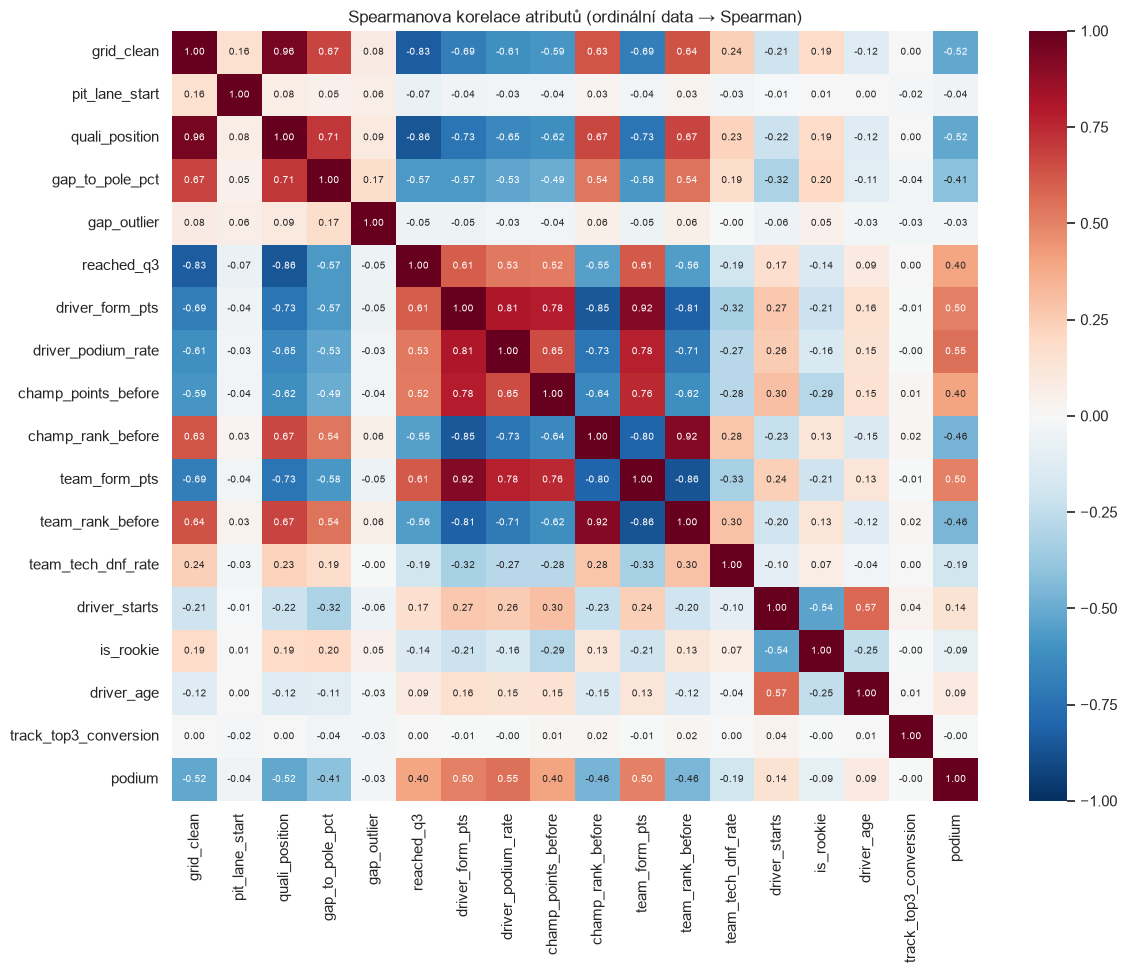

Nejsilnější vztah k cíli:
driver_podium_rate       0.55
quali_position          -0.52
grid_clean              -0.52
driver_form_pts          0.50
team_form_pts            0.50
champ_rank_before       -0.46
team_rank_before        -0.46
gap_to_pole_pct         -0.41
champ_points_before      0.40
reached_q3               0.40
team_tech_dnf_rate      -0.19
driver_starts            0.14
is_rookie               -0.09
driver_age               0.09
pit_lane_start          -0.04
gap_outlier             -0.03
track_top3_conversion   -0.00


In [23]:
corr = df[FEATURES + ["podium"]].corr(method="spearman")
plt.figure(figsize=(13, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot_kws={"size": 7})
plt.title("Spearmanova korelace atributů (ordinální data → Spearman)"); plt.show()

print("Nejsilnější vztah k cíli:")
print(corr["podium"].drop("podium").sort_values(key=abs, ascending=False).round(2).to_string())

In [24]:
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename("rho").to_frame().query("abs(rho) > 0.8").sort_values("rho", key=abs, ascending=False))
pairs.round(2)

rho
grid_clean        quali_position      0.96
driver_form_pts   team_form_pts       0.92
champ_rank_before team_rank_before    0.92
team_form_pts     team_rank_before   -0.86
quali_position    reached_q3         -0.86
driver_form_pts   champ_rank_before  -0.85
grid_clean        reached_q3         -0.83
driver_form_pts   team_rank_before   -0.81
                  driver_podium_rate  0.81
champ_rank_before team_form_pts      -0.80

**Multikolinearita** (přednáška 03): silně korelované dvojice nesou téměř stejnou informaci. Nejvýraznější jsou:
- `grid_clean` × `quali_position` (ρ ≈ 0,96): startovní pozice je kvalifikace upravená o penalizace
- `driver_form_pts` × `team_form_pts` (ρ ≈ 0,92): týmoví kolegové jezdí ve stejném autě
- `champ_rank_before` × `team_rank_before` (ρ ≈ 0,92)

Vadí to hlavně lineárním modelům (logistická regrese), u kterých pak nejdou spolehlivě interpretovat váhy. Rozhodovací stromy jsou vůči tomu odolné. Pro lineární modely proto z každé dvojice ponecháme jeden atribut. Alternativou je redukce dimenze pomocí PCA (přednáška 03).

`track_top3_conversion` sám o sobě s cílem nekoreluje (ρ ≈ 0). To dává smysl: trať neříká, *kdo* bude na pódiu, ale *jak moc* rozhoduje startovní pozice. Uplatní se až v kombinaci s gridem, kterou umí zachytit např. rozhodovací strom. Zda pomáhá, ověříme v modelování (výběr atributů).

## 8. Uložení tabulky pro modelování
Uložíme identifikátory (pro rozdělení podle sezón a pozdější kontrolu), vstupní atributy a cílovou třídu. Kategorie `team` a `circuit_id` ponecháváme, zakódují se v pipeline (one-hot, target encoding).

In [25]:
ID_COLS = ["season", "round", "date", "race_name", "circuit_id", "driver_id", "team"]
out = df[ID_COLS + FEATURES + ["position", "podium"]]
out.to_csv(f"{DATA}/features.csv", index=False)
print("Uloženo data/features.csv:", out.shape)
out.groupby("season").size().to_frame("instancí").T

Uloženo data/features.csv: (5479, 26)


season,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
instancí,407,378,462,400,420,420,340,440,440,440,479,479,374


## Shrnutí

**Porozumění datům**
- 5 479 instancí, sezóny 2014–2026; na pódiu je 14,7 % instancí → nevyvážené třídy, hodnotit pomocí F1 a ROC (přednáška 04)
- nejsilnějším prediktorem je startovní pozice, ale výsledek neurčuje: šum tvoří poruchy, nehody a diskvalifikace

**Příprava dat**
- vyřešené nekonzistence: 67 statusů → 6 skupin, přejmenované týmy → stáje, `grid = 0` → poslední místo + příznak
- chybějící časy Q2/Q3 → indikátor `reached_q3`; odlehlé ztráty v kvalifikaci → ořez na 99. percentil + příznak
- 11 odvozených atributů o jezdci, týmu a trati, počítaných výhradně z předchozích závodů

**Další krok – `Modelovani.ipynb`:** rozdělení dat podle sezón, `Pipeline` s imputací, kódováním a škálováním, baseline podle startovní pozice, rozhodovací strom (přednáška 05) a další klasifikátory.